# RL-10 : Reward shaping et curriculum learning en C#

**Durée :** 45–50 minutes · **Noyau :** .NET 9 / C#

[Retour à la série](README.md) · [Version Python](RL-10-Reward-Shaping-Curriculum-Python.ipynb)

**Objectifs :** comparer quatre signaux d'apprentissage, distinguer mesure empirique et garantie de Bellman. Prérequis : MDP et Q-learning.

## 1. Labyrinthe sparse

Le labyrinthe est de taille 8×8. Une transition bloquée par un mur conserve l'état ; chaque pas coûte −1, sauf l'entrée au but qui rapporte 0. Le départ est en bas à gauche, le but en haut à droite.


In [1]:
#nullable enable
using System;

using System.Linq;

using System.Collections.Generic;

public class Maze
{

    public const int Goal = 7, Start = 56;
    public const double Gamma = .99, Alpha = .1, Eps = .1;

    public bool Wall(int s) => s % 8 == 4 && s / 8 >= 1 && s / 8 <= 6 && s / 8 != 3;

    public int Distance(int s) => s / 8 + Math.Abs(s % 8 - 7);

    public (int next, double reward, bool done) Step(int s, int a)
    {

        int r = s / 8, c = s % 8;
        int rr = r + (a == 0 ? -1 : a == 1 ? 1 : 0), cc = c + (a == 2 ? -1 : a == 3 ? 1 : 0);

        int n = rr < 0 || rr >= 8 || cc < 0 || cc >= 8 || Wall(rr * 8 + cc) ? s : rr * 8 + cc;

        return (n, n == Goal ? 0 : -1, n == Goal);

    }

    public int Choose(double[,] q, int s, Random rng)
    {

        if (rng.NextDouble() < Eps) return rng.Next(4);

        double best = Enumerable.Range(0, 4).Max(a => q[s, a]);
        int[] ties = Enumerable.Range(0, 4).Where(a => q[s, a] == best).ToArray();
        return ties[rng.Next(ties.Length)];

    }

    public (double[,], double[]) Learn(int mode, int seed)
    {

        var q = new double[64, 4];
        var returns = new double[2000];
        var rng = new Random(seed);
        int[] starts ={
7,14,28,42,56}
       ;

        for (int ep = 0; ep < 2000; ep++)
        {
            int phase = ep / 400;
            int s = mode == 3 ? (phase < 4 && rng.NextDouble() < .3 ? Start : starts[phase]) : Start;
            double total = 0;

            for (int t = 0; t < 500; t++)
            {
                int a = Choose(q, s, rng);
                var (n, r, done) = Step(s, a);
                double shaped = r;

                if (mode == 1) shaped += Gamma * (done ? 0 : -Distance(n)) + Distance(s);

                if (mode == 2) shaped += 2 * (Distance(s) - (done ? 0 : Distance(n)));

                double target = shaped + (done ? 0 : Gamma * Enumerable.Range(0, 4).Max(b => q[n, b]));
                q[s, a] += Alpha * (target - q[s, a]);
                total += r;
                if (done) break;
                s = n;

            }
            returns[ep] = total;

        }
        return (q, returns);

    }

    public double[,] Bellman(bool shaped)
    {
        var v = new double[64];
        var q = new double[64, 4];

        for (int i = 0; i < 3000; i++)
        {
            var nv = new double[64];
            for (int s = 0; s < 64; s++)
            {
                if (s == Goal || Wall(s)) continue;
                for (int a = 0; a < 4; a++)
                {
                    var (n, r, done) = Step(s, a);
                    if (shaped) r += Gamma * (done ? 0 : -Distance(n)) + Distance(s);
                    q[s, a] = r + (done ? 0 : Gamma * v[n]);
                }
                nv[s] = Enumerable.Range(0, 4).Max(a => q[s, a]);
            }
            v = nv;
        }
        return q;

    }

}



Console.WriteLine("Labyrinthe, transitions et apprentissage définis.");

The below script needs to be able to find the current output cell; this is an easy method to get it.

Labyrinthe, transitions et apprentissage définis.


### Carte du labyrinthe

Le départ (D) est en bas à gauche et le but (B) en haut à droite. Les cases foncées sont des murs ; la brèche est située à la quatrième ligne.

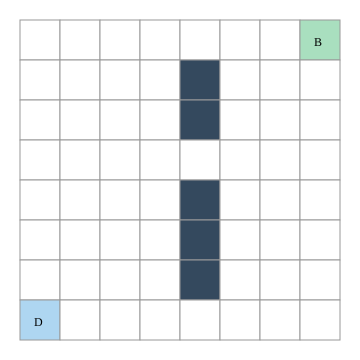

In [2]:
using Microsoft.DotNet.Interactive.Formatting;
record MazeSvg(string Text);
Formatter.Register<MazeSvg>((f, w) => w.Write(f.Text), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(MazeSvg), "image/svg+xml");
var mazeForDrawing = new Maze();
var mapSvg = new System.Text.StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='360' height='360' viewBox='0 0 360 360' role='img' aria-label='Labyrinthe 8 par 8, départ D et but B'>");
for (int r = 0; r < 8; r++) for (int c = 0; c < 8; c++) {
    int state = r * 8 + c;
    string color = mazeForDrawing.Wall(state) ? "#34495e" : state == Maze.Start ? "#aed6f1" : state == Maze.Goal ? "#a9dfbf" : "white";
    mapSvg.Append($"<rect x='{20+c*40}' y='{20+r*40}' width='40' height='40' fill='{color}' stroke='#999'/>");
    if (state == Maze.Start || state == Maze.Goal)
        mapSvg.Append($"<text x='{34+c*40}' y='{46+r*40}'>{(state==Maze.Start ? "D" : "B")}</text>");
}
mapSvg.Append("</svg>");
display(new MazeSvg(mapSvg.ToString()));

## 2. Quatre apprentissages

La récompense originale est journalisée dans tous les bras. Le potentiel est l’opposé de la distance de Manhattan ; le façonnage heuristique est distinct. Le curriculum utilise cinq départs et réintroduit le départ réel avec probabilité 30 %. Chaque bras utilise cinq graines, 2 000 épisodes et au plus 500 pas.


### Q-learning et départages

La mise à jour est $Q(s,a)\leftarrow Q(s,a)+\alpha[r'+\gamma\max_bQ(s',b)-Q(s,a)]$, avec valeur future nulle au terminal. Ici $\alpha=0,1$, $\gamma=0,99$ et $\epsilon=0,1$. En exploration, les quatre actions sont équiprobables ; en exploitation, le tirage est uniforme parmi **toutes** les actions de valeur maximale. La table stocke le signal façonné, mais les courbes mesurent la récompense originale.

### Curriculum

Les cinq départs sont $(0,7),(1,6),(3,4),(5,2),(7,0)$, présentés en phases de 400 épisodes. Dans les quatre premières phases, 30 % des épisodes partent aussi du départ réel. Le premier départ coïncide avec le but : on conserve néanmoins la même transition que dans le source, sans considérer automatiquement l'épisode comme terminé avant le premier pas.


In [3]:
var env = new Maze();
if (env.Step(Maze.Start, 1).next != Maze.Start || env.Step(6,3) != (7,0.0,true) || env.Step(28,0).next != 28) throw new Exception("Transition inattendue");
var names = new[]{"Baseline", "Potentiel", "Heuristique", "Curriculum"};
var seeds = new[]{0,1,7,42,99};
var curves = new double[4][];
for(int mode=0; mode<4; mode++) {
 var runs=seeds.Select(seed=>env.Learn(mode,seed).Item2).ToArray();
 curves[mode]=Enumerable.Range(0,2000).Select(i=>runs.Average(r=>r[i])).ToArray();
 var moving=Enumerable.Range(49,1951).Select(i=>curves[mode].Skip(i-49).Take(50).Average()).ToArray();
 int threshold=Array.FindIndex(moving,x=>x>=-30);
 Console.WriteLine($"{names[mode],-12}: MA-50 finale {moving[^1]:F3}, premier seuil {(threshold<0 ? "non atteint" : (threshold+50).ToString())}");
}


Baseline    : MA-50 finale -14.576, premier seuil 193


Potentiel   : MA-50 finale -14.572, premier seuil 50


Heuristique : MA-50 finale -14.684, premier seuil 50


Curriculum  : MA-50 finale -14.656, premier seuil 103


### Lecture

La moyenne mobile décrit la vitesse observée sur ces graines. Le curriculum change les positions de départ : ses retours ne mesurent donc pas toujours la même distribution de départ que les autres bras. Le premier franchissement ne démontre pas la convergence optimale.

## 3. Courbes de récompense originale


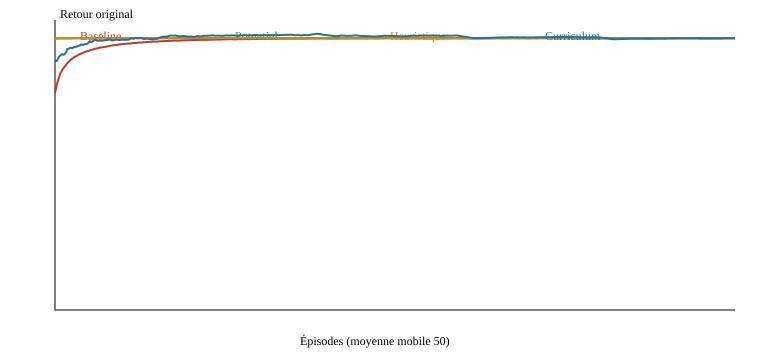

In [4]:
using Microsoft.DotNet.Interactive.Formatting;
using System.Globalization;
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
record FigureSvg(string Text);
Formatter.Register<FigureSvg>((f, w) => w.Write(f.Text), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(FigureSvg), "image/svg+xml");
var colors=new[]{"#c0392b","#218c56","#d68910","#2471a3"};
var svg=new System.Text.StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='760' height='360' viewBox='0 0 760 360'><rect width='760' height='360' fill='white'/><path d='M55 20 V310 H735' fill='none' stroke='black'/><text x='300' y='345'>Épisodes (moyenne mobile 50)</text><text x='60' y='18'>Retour original</text>");
for(int m=0;m<4;m++){var points=Enumerable.Range(49,1951).Where(i=>i%5==4).Select(i=>$"{55+(i-49)*680.0/1950:F1},{310-Math.Clamp((curves[m].Skip(i-49).Take(50).Average()+500)/500,0,1)*280:F1}");svg.Append($"<polyline fill='none' stroke='{colors[m]}' stroke-width='2' points='{string.Join(" ",points)}'/><text x='{80+m*155}' y='40' fill='{colors[m]}'>{names[m]}</text>");}
svg.Append("</svg>"); display(new FigureSvg(svg.ToString()));


## 4. Mesure empirique et oracle

Deux apprentissages finis à la graine 42 donnent un test empirique : leur action gloutonne peut différer. L’oracle calcule séparément les valeurs optimales par itération de Bellman et compare tous les maximisateurs ; le potentiel terminal est nul.


### Garantie par télescopage

Pour une trajectoire terminée au temps $T$, avec $\Phi(s_T)=0$ :

$$G'=\sum_{t=0}^{T-1}\gamma^t[r_t+\gamma\Phi(s_{t+1})-\Phi(s_t)]=G-\Phi(s_0).$$

Ce décalage ne dépend pas de la première action. Pour chaque état et chaque action, $Q'^*(s,a)=Q^*(s,a)-\Phi(s)$ : **tout l'ensemble des maximisateurs**, y compris les égalités, est conservé. La condition terminale et le même facteur $\gamma$ sont nécessaires à ce calcul. Le façonnage naïf utilise un coefficient qui ne satisfait pas en général cette forme avec $\gamma=0,99$.


In [5]:
var qb=env.Learn(0,42).Item1; var qp=env.Learn(1,42).Item1;
int arg(double[,] q,int s)=>Enumerable.Range(0,4).OrderByDescending(a=>q[s,a]).First();
Console.WriteLine($"Empirique au départ : baseline [{string.Join(", ",Enumerable.Range(0,4).Select(a=>qb[Maze.Start,a].ToString("F4")))}], potentiel [{string.Join(", ",Enumerable.Range(0,4).Select(a=>qp[Maze.Start,a].ToString("F4")))}]");
Console.WriteLine($"Actions empiriques : {arg(qb,Maze.Start)} et {arg(qp,Maze.Start)} ; identiques : {arg(qb,Maze.Start)==arg(qp,Maze.Start)}");
var exact=env.Bellman(false); var shaped=env.Bellman(true); double error=0; int sets=0;
for(int s=0;s<64;s++){if(s==Maze.Goal||env.Wall(s))continue;double max=Enumerable.Range(0,4).Max(a=>exact[s,a]),maxp=Enumerable.Range(0,4).Max(a=>shaped[s,a]);for(int a=0;a<4;a++){error=Math.Max(error,Math.Abs(shaped[s,a]-exact[s,a]-env.Distance(s)));if((Math.Abs(exact[s,a]-max)<1e-8)!=(Math.Abs(shaped[s,a]-maxp)<1e-8))sets++;}}
Console.WriteLine($"Oracle : erreur maximale Q′ − Q + φ = {error:E3}, différences d'appartenance aux ensembles de maximisateurs = {sets}");
if(error>1e-8||sets!=0)throw new Exception("Invariance de Bellman non vérifiée");


Empirique au départ : baseline [-12.2460, -13.0851, -13.0819, -12.2460], potentiel [1.7521, 0.8668, 0.8633, 1.6628]


Actions empiriques : 3 et 0 ; identiques : False


Oracle : erreur maximale Q′ − Q + φ = 3.553E-015, différences d'appartenance aux ensembles de maximisateurs = 0


### Interprétation

La comparaison empirique dépend des valeurs apprises à budget fini. La relation exacte et les ensembles d’actions ex æquo proviennent, eux, de Bellman : ils portent la garantie, sans imposer le résultat du test empirique. Le façonnage heuristique ne bénéficie pas de cette garantie. La récompense apprise en RLHF ne constitue pas automatiquement un potentiel préservant la politique.


## Du shaping au RLHF

Un modèle de récompense entraîné sur des préférences fournit un signal appris plutôt que le potentiel manuel étudié ici. La régularisation KL limite l'écart à une politique de référence ; elle n'est pas, en général, une transformation potentielle garantissant l'invariance de la politique optimale. Le lien est une analogie sur la conception du signal, non une équivalence mathématique. DPO optimise directement des préférences et ne requiert pas le même entraînement explicite d'un modèle de récompense.

## 5. Exercices

### Exercice 1 — Potentiels

Comparez distance euclidienne, potentiel constant avec condition terminale explicite et Manhattan amplifié. Mesurez leurs effets sur les retours et l’oracle.


In [6]:
#nullable enable
// TODO : fournir trois potentiels et entraîner le même Q-learning pour chacun.
// Le potentiel terminal doit rester nul, y compris pour le potentiel constant.
Dictionary<string, Func<int, double>>? ConstruirePotentiels(Maze labyrinthe)
{
    return null; // TODO étudiant : Euclidien, constant, Manhattan amplifié
}
var potentiels = ConstruirePotentiels(env);
if (potentiels is null) Console.WriteLine("Exercice à compléter : définir trois potentiels.");
else {
    if (potentiels.Count != 3 || potentiels.Values.Any(phi => Math.Abs(phi(Maze.Goal)) > 1e-10))
        throw new ArgumentException("Trois potentiels avec valeur terminale nulle sont attendus.");
    Console.WriteLine("Potentiels prêts : adapter Learn pour les comparer sur les cinq graines.");
}

Exercice à compléter : définir trois potentiels.


### Exercice 2 — Curriculum

Faites varier le nombre de phases entre 2, 3, 5 et 10. Comparez les retours depuis le vrai départ, à budget commun.


In [7]:
#nullable enable
// TODO : généraliser les positions et répartir exactement 2 000 épisodes entre les phases.
double[]? CurriculumVariable(Maze labyrinthe, int phases, int seed)
{
    return null; // TODO étudiant
}
foreach (int phases in new[] { 2, 3, 5, 10 }) {
    var retours = CurriculumVariable(env, phases, 42);
    if (retours is null) Console.WriteLine($"Exercice à compléter : {phases} phases.");
    else if (retours.Length != 2000) throw new ArgumentException("Le budget doit être de 2 000 épisodes.");
    else Console.WriteLine($"{phases} phases, retour final : {retours.TakeLast(50).Average():F2}");
}

Exercice à compléter : 2 phases.


Exercice à compléter : 3 phases.


Exercice à compléter : 5 phases.


Exercice à compléter : 10 phases.


### Exercice 3 — Leurre

Construisez un labyrinthe où un leurre proche en distance mène à un détour ; montrez si le façonnage heuristique change la politique optimale.


In [8]:
#nullable enable
// TODO : construire un MDP avec un leurre, puis renvoyer les actions optimales
(int baseline, int heuristique, int potentiel)? ComparerLeurre()
{
    return null; // TODO étudiant : résoudre le MDP pour les trois récompenses
}
var leurre = ComparerLeurre();
if (leurre is null) Console.WriteLine("Exercice à compléter : construire le leurre.");
else {
    var (baseline, heuristique, potentiel) = leurre.Value;
    Console.WriteLine($"Actions : baseline={baseline}, heuristique={heuristique}, potentiel={potentiel}");
    if (baseline != potentiel) Console.WriteLine("Vérifiez le potentiel et le traitement terminal.");
}

Exercice à compléter : construire le leurre.


## À retenir

Le façonnage potentiel ajoute $\gamma\Phi(s')-\Phi(s)$ et conserve les maximisateurs sous les hypothèses du modèle. Un curriculum modifie la distribution des départs et l’expérience finie ne démontre pas une propriété asymptotique.

## Vérifiez votre compréhension

Pourquoi une action empirique différente ne contredit-elle pas l’oracle ?

<details><summary>Éléments de réponse</summary>

Les tables de Q-learning sont approchées et les actions peuvent être proches ; l’oracle résout le problème de Bellman et compare tous les maximisateurs.

</details>

## Pour aller plus loin

Ng, Harada et Russell (1999), *Policy Invariance Under Reward Transformations*. Bengio et al. (2009), *Curriculum Learning*.
